# 🏆 Challenge solution: plasma proteomics and intestinal organ ageing

A worked solution to the challenge at the end of `Intro_toML.ipynb`. It follows the challenge's six steps and the
rules from Tasks 1–3: everything that learns from data (scaling, feature selection, PCA, UMAP) is fitted on the
**training set only**, then applied to the test set.

Run it from the `tutorial_4/solutions` folder (the data is read from `../data`).

## 1. Data loading & libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay)
from imblearn.metrics import specificity_score
import umap

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

/Users/meb22/opt/anaconda3/envs/intropython/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv("../data/Data_for_challenge.csv", index_col="patient_id")

clinical = ["constipation", "hyposmia", "UPDRS_III"]
target = "intestinal_organ_age"
proteins = [c for c in df.columns if c not in clinical + [target]]

print(df.shape)
print(f"{len(proteins)} proteins, {len(clinical)} clinical variables, target: {target}")
print("Missing values:", df.isna().sum().sum())
df[clinical + [target]].describe().round(2)

(500, 1467)
1463 proteins, 3 clinical variables, target: intestinal_organ_age
Missing values: 0


,constipation,hyposmia,UPDRS_III,intestinal_organ_age
count,500.00,500.00,500.00,500.00
mean,12.48,30.04,50.73,0.50
std,5.22,4.66,19.91,0.18
min,0.00,13.00,6.00,0.00
25%,9.00,27.00,37.00,0.37
50%,12.00,30.00,49.00,0.50
75%,16.00,33.00,63.00,0.62
max,29.00,40.00,117.00,1.00


There are **1,463 proteins for 500 people**: many more features than samples. Keep this in mind for the regression on
all features.

## 2. Relationships with the clinical variables

Spearman correlations (the clinical scores are bounded and not all normal), with a scatter plot for each.
- `constipation`: Wexner score, 0–30, higher = more constipation (15 or more is the clinical cut-off)
- `hyposmia`: UPSIT score, higher = **better** smell (18 or less = anosmia)
- `UPDRS_III`: motor symptoms, 0–132, higher = more severe

In [3]:
rows = []
for var in clinical:
    rho, p = stats.spearmanr(df[var], df[target])
    rows.append({"variable": var, "Spearman rho": rho, "p-value": p})
corr_clinical = pd.DataFrame(rows).set_index("variable")
corr_clinical["FDR p"] = multipletests(corr_clinical["p-value"], method="fdr_bh")[1]
corr_clinical.style.format({"Spearman rho": "{:.3f}", "p-value": "{:.2e}", "FDR p": "{:.2e}"})

,Spearman rho,p-value,FDR p
variable,,,
constipation,0.812,9.00e-119,2.70e-118
hyposmia,-0.719,9.37e-81,1.41e-80
UPDRS_III,0.538,7.14e-39,7.14e-39


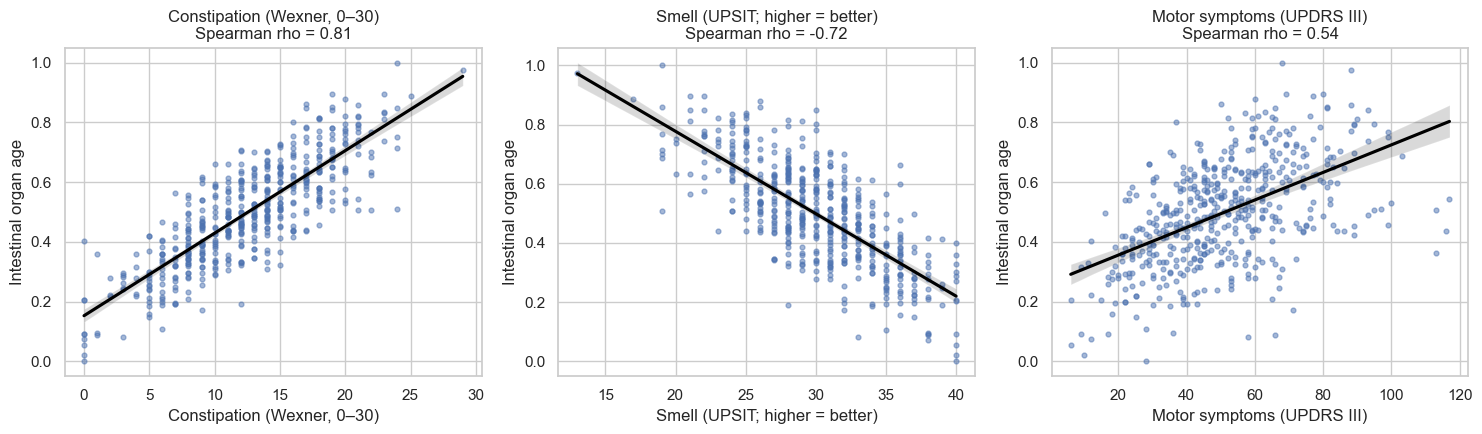

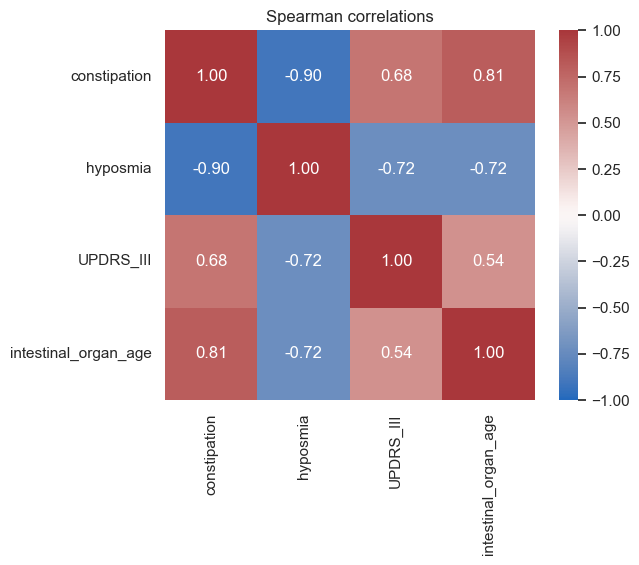

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
labels = {"constipation": "Constipation (Wexner, 0–30)", "hyposmia": "Smell (UPSIT; higher = better)",
          "UPDRS_III": "Motor symptoms (UPDRS III)"}
for ax, var in zip(axes, clinical):
    sns.regplot(data=df, x=var, y=target, ax=ax, scatter_kws={"s": 12, "alpha": 0.5}, line_kws={"color": "black"})
    rho = corr_clinical.loc[var, "Spearman rho"]
    ax.set_title(f"{labels[var]}\nSpearman rho = {rho:.2f}")
    ax.set_xlabel(labels[var]); ax.set_ylabel("Intestinal organ age")
plt.tight_layout(); plt.show()

sns.heatmap(df[clinical + [target]].corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True)
plt.title("Spearman correlations"); plt.show()

## 3. Regression: predict organ age

One 80/20 split, used for every approach so they are compared on the same test patients.

In [5]:
X = df[proteins]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(len(X_train), "training and", len(X_test), "test patients")

scaler = StandardScaler().fit(X_train)            # fitted on the training set only
X_train_s = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=proteins)
X_test_s = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=proteins)

results = []   # one row per feature set, filled in below

def evaluate_regression(name, Xtr, Xte):
    model = LinearRegression().fit(Xtr, y_train)
    pred_tr, pred_te = model.predict(Xtr), model.predict(Xte)
    row = {"features": name, "n features": Xtr.shape[1],
           "train R²": r2_score(y_train, pred_tr),
           "test R²": r2_score(y_test, pred_te),
           "test MAE": mean_absolute_error(y_test, pred_te),
           "test MSE": mean_squared_error(y_test, pred_te)}
    results.append(row)
    return model, pred_te, row

400 training and 100 test patients


### 3.1 All 1,463 proteins

In [6]:
model_all, pred_all, row = evaluate_regression("All proteins", X_train_s, X_test_s)
pd.Series(row).to_frame("value")

,value
features,All proteins
n features,1463
train R²,1.0
test R²,0.736367
test MAE,0.07858
test MSE,0.009037


With more features (1,463) than training patients (400), linear regression can fit the training set **perfectly**
(train R² = 1): it has memorised it. The test R² shows how badly that generalises. This is the **curse of
dimensionality** from Task 2 and Task 3.

### 3.2 Statistically selected proteins

Pearson correlation between each protein and organ age, **on the training set only**, with Benjamini–Hochberg FDR
correction for 1,463 tests.

In [7]:
r_p = [stats.pearsonr(X_train[p], y_train) for p in proteins]
corr_proteins = pd.DataFrame({"protein": proteins, "r": [r for r, _ in r_p], "p": [p for _, p in r_p]})
corr_proteins["FDR p"] = multipletests(corr_proteins["p"], method="fdr_bh")[1]
selected = corr_proteins.loc[corr_proteins["FDR p"] < 0.05].sort_values("FDR p")
print(f"{len(selected)} of {len(proteins)} proteins are significant after FDR correction")
selected.head(15).style.format({"r": "{:.3f}", "p": "{:.2e}", "FDR p": "{:.2e}"})

338 of 1463 proteins are significant after FDR correction


,protein,r,p,FDR p
629,ITGAV,0.790,1.62e-86,2.37e-83
1326,VEGFA,0.702,1.59e-60,1.17e-57
1011,FAS,0.667,9.50e-53,4.63e-50
99,IL6,0.658,6.01e-51,2.20e-48
49,TNF,0.652,7.96e-50,2.33e-47
334,MMP9,0.381,3.00e-15,7.32e-13
108,EREG,0.311,1.91e-10,3.99e-08
128,AGR2,0.285,6.26e-09,1.14e-06
86,DCTN6,0.267,5.65e-08,8.59e-06
101,CLPP,0.267,5.87e-08,8.59e-06


In [8]:
# Every protein with FDR q < 0.05 (training set only), not just the top 15
fdr_table = (corr_proteins.loc[corr_proteins["FDR p"] < 0.05, ["protein", "r", "p", "FDR p"]]
             .sort_values("p").reset_index(drop=True))
fdr_table.index += 1
print(f"{len(fdr_table)} proteins with FDR q < 0.05 "
      f"({(fdr_table['r'] > 0).sum()} positive, {(fdr_table['r'] < 0).sum()} negative correlations)")
with pd.option_context("display.max_rows", None):
    display(fdr_table.style.format({"r": "{:.3f}", "p": "{:.2e}", "FDR p": "{:.2e}"}))

338 proteins with FDR q < 0.05 (126 positive, 212 negative correlations)


,protein,r,p,FDR p
1,ITGAV,0.790,1.62e-86,2.37e-83
2,VEGFA,0.702,1.59e-60,1.17e-57
3,FAS,0.667,9.50e-53,4.63e-50
4,IL6,0.658,6.01e-51,2.20e-48
5,TNF,0.652,7.96e-50,2.33e-47
6,MMP9,0.381,3.00e-15,7.32e-13
7,EREG,0.311,1.91e-10,3.99e-08
8,AGR2,0.285,6.26e-09,1.14e-06
9,DCTN6,0.267,5.65e-08,8.59e-06
10,CLPP,0.267,5.87e-08,8.59e-06


In [9]:
sel = selected["protein"].tolist()
if sel:
    model_sel, pred_sel, row = evaluate_regression("Significant proteins (FDR)", X_train_s[sel], X_test_s[sel])
    display(pd.Series(row).to_frame("value"))
else:
    pred_sel = None
    print("No protein passes FDR < 0.05: this feature set is skipped")

,value
features,Significant proteins (FDR)
n features,338
train R²,0.976457
test R²,0.159972
test MAE,0.140503
test MSE,0.028795


FDR keeps **hundreds** of proteins, most of them only weakly correlated with organ age. With that many features for
400 training patients, linear regression still overfits: compare the train and test R². A stricter correction,
**Bonferroni** (which controls the chance of *any* false positive), keeps only the strongest proteins.

In [10]:
corr_proteins["Bonferroni p"] = multipletests(corr_proteins["p"], method="bonferroni")[1]
strong = corr_proteins.loc[corr_proteins["Bonferroni p"] < 0.05].sort_values("p")
print(f"{len(strong)} proteins survive Bonferroni correction:", ", ".join(strong["protein"].head(20)), "…" if len(strong) > 20 else "")
sel_b = strong["protein"].tolist()
if sel_b:
    model_selb, pred_selb, row = evaluate_regression("Significant proteins (Bonferroni)", X_train_s[sel_b], X_test_s[sel_b])
    display(pd.Series(row).to_frame("value"))
else:
    pred_selb = None
    print("No protein survives Bonferroni: this feature set is skipped")

45 proteins survive Bonferroni correction: ITGAV, VEGFA, FAS, IL6, TNF, MMP9, EREG, AGR2, DCTN6, CLPP, NEFL, FKBP7, DPEP1, KIRREL2, CASP1, VWC2, MRPL46, NAAA, PHOSPHO1, PPP3R1 …


,value
features,Significant proteins (Bonferroni)
n features,45
train R²,0.863498
test R²,0.830156
test MAE,0.06222
test MSE,0.005822


### 3.3 PCA and UMAP features

Both are fitted on the scaled **training** proteins and then applied to the test set. For PCA we keep enough
components to explain 80% of the training variance, as in Task 3; for UMAP we use 10 dimensions.

In [11]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_s)
n80 = int(np.argmax(np.cumsum(pca_full.explained_variance_ratio_) >= 0.80) + 1)
pca = PCA(n_components=n80, random_state=RANDOM_STATE).fit(X_train_s)
P_train, P_test = pca.transform(X_train_s), pca.transform(X_test_s)
print(f"{n80} principal components explain 80% of the training variance")
model_pca, pred_pca, row = evaluate_regression(f"PCA ({n80} PCs)", P_train, P_test)
pd.Series(row).to_frame("value")

157 principal components explain 80% of the training variance


,value
features,PCA (157 PCs)
n features,157
train R²,0.910929
test R²,0.701566
test MAE,0.084702
test MSE,0.01023


In [12]:
reducer = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit(X_train_s)
U_train, U_test = reducer.transform(X_train_s), reducer.transform(X_test_s)
model_umap, pred_umap, row = evaluate_regression("UMAP (10 dims)", U_train, U_test)
pd.Series(row).to_frame("value")

/Users/meb22/opt/anaconda3/envs/intropython/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,value
features,UMAP (10 dims)
n features,10
train R²,0.136644
test R²,0.069082
test MAE,0.139976
test MSE,0.03191


/Users/meb22/opt/anaconda3/envs/intropython/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


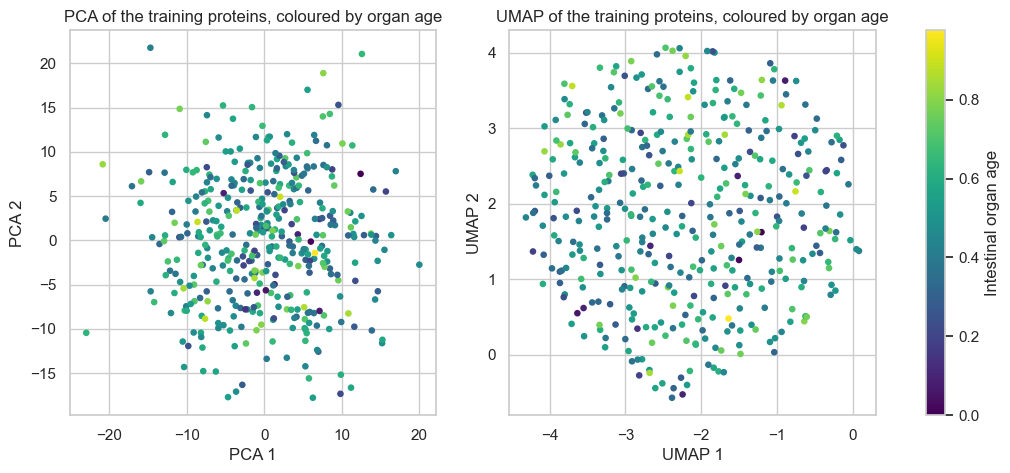

In [13]:
# 2D embeddings of the training set, coloured by organ age
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_s)
umap2 = umap.UMAP(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_s)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, emb, name in [(axes[0], pca2, "PCA"), (axes[1], umap2, "UMAP")]:
    s = ax.scatter(emb[:, 0], emb[:, 1], c=y_train, cmap="viridis", s=14)
    ax.set_title(f"{name} of the training proteins, coloured by organ age"); ax.set_xlabel(f"{name} 1"); ax.set_ylabel(f"{name} 2")
plt.colorbar(s, ax=axes, label="Intestinal organ age")
plt.show()

In [14]:
reg_table = pd.DataFrame(results).set_index("features")
reg_table.round(3)

,n features,train R²,test R²,test MAE,test MSE
features,,,,,
All proteins,1463,1.000,0.736,0.079,0.009
Significant proteins (FDR),338,0.976,0.160,0.141,0.029
Significant proteins (Bonferroni),45,0.863,0.830,0.062,0.006
PCA (157 PCs),157,0.911,0.702,0.085,0.010
UMAP (10 dims),10,0.137,0.069,0.140,0.032


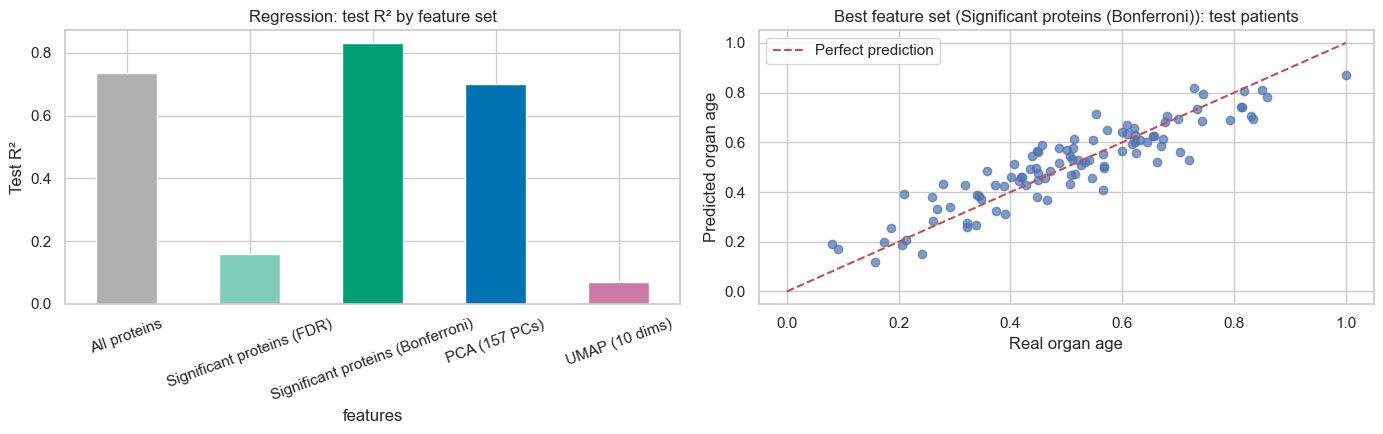

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
reg_table["test R²"].plot.bar(ax=axes[0], color=["#B0B0B0", "#7FCDB8", "#009E73", "#0072B2", "#CC79A7"])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Test R²"); axes[0].set_title("Regression: test R² by feature set"); axes[0].tick_params(axis="x", rotation=20)
best = reg_table["test R²"].idxmax()
pred_best = {"All proteins": pred_all, "Significant proteins (FDR)": pred_sel, "Significant proteins (Bonferroni)": pred_selb}.get(best, pred_pca if best.startswith("PCA") else pred_umap)
axes[1].scatter(y_test, pred_best, alpha=0.7)
axes[1].plot([0, 1], [0, 1], "r--", label="Perfect prediction")
axes[1].set_xlabel("Real organ age"); axes[1].set_ylabel("Predicted organ age"); axes[1].legend()
axes[1].set_title(f"Best feature set ({best}): test patients")
plt.tight_layout(); plt.show()

## 4. Classification: young vs old organs

`young` = organ age < 0.5, `old` = organ age ≥ 0.5. A new **stratified** split keeps the same ratio of young and old in
both sets. Four feature sets, all built on the training set only:
1. proteins that differ between young and old (Welch's t-test + FDR),
2. the same test with the stricter Bonferroni correction,
3. UMAP (10 dimensions),
4. PCA (80% of the variance).

In [16]:
y_cls = (df[target] >= 0.5).astype(int)           # 1 = old, 0 = young
print(y_cls.value_counts().rename({0: "young", 1: "old"}))
Xc_train, Xc_test, yc_train, yc_test = train_test_split(df[proteins], y_cls, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cls)

sc = StandardScaler().fit(Xc_train)
Xc_train_s = pd.DataFrame(sc.transform(Xc_train), index=Xc_train.index, columns=proteins)
Xc_test_s = pd.DataFrame(sc.transform(Xc_test), index=Xc_test.index, columns=proteins)

cls_results, confusion = [], {}

def evaluate_classifier(name, Xtr, Xte):
    clf = LogisticRegression(max_iter=5000).fit(Xtr, yc_train)
    pred = clf.predict(Xte)
    cls_results.append({"features": name, "n features": Xtr.shape[1],
                        "accuracy": accuracy_score(yc_test, pred), "precision": precision_score(yc_test, pred),
                        "recall (sensitivity)": recall_score(yc_test, pred), "specificity": specificity_score(yc_test, pred)})
    confusion[name] = confusion_matrix(yc_test, pred)
    return clf

intestinal_organ_age
young    255
old      245
Name: count, dtype: int64


In [17]:
# 1–2. Welch's t-test, young vs old, on the training set only, with FDR and Bonferroni correction
old_tr, young_tr = Xc_train[yc_train == 1], Xc_train[yc_train == 0]
t, p = stats.ttest_ind(old_tr[proteins], young_tr[proteins], equal_var=False)
welch = pd.DataFrame({"protein": proteins,
                      "mean old − young": (old_tr[proteins].mean() - young_tr[proteins].mean()).values,
                      "t": t, "p": p})
welch["FDR p"] = multipletests(welch["p"], method="fdr_bh")[1]
welch["Bonferroni p"] = multipletests(welch["p"], method="bonferroni")[1]
welch = welch.sort_values("p").reset_index(drop=True)
welch.index += 1
sel_cls = welch.loc[welch["FDR p"] < 0.05, "protein"].tolist()
sel_cls_b = welch.loc[welch["Bonferroni p"] < 0.05, "protein"].tolist()
print(f"{len(sel_cls)} proteins differ between young and old organs (FDR < 0.05); {len(sel_cls_b)} survive Bonferroni")
display(welch.head(15).style.format({"mean old − young": "{:.3f}", "t": "{:.2f}",
                                     "p": "{:.2e}", "FDR p": "{:.2e}", "Bonferroni p": "{:.2e}"}))
for name, feats in [("Significant proteins (FDR)", sel_cls), ("Significant proteins (Bonferroni)", sel_cls_b)]:
    if feats:
        evaluate_classifier(name, Xc_train_s[feats], Xc_test_s[feats])
    else:
        print(f"{name}: no significant proteins, skipped")

# 2. UMAP and 3. PCA, fitted on the training set only
red_c = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE).fit(Xc_train_s)
evaluate_classifier("UMAP (10 dims)", red_c.transform(Xc_train_s), red_c.transform(Xc_test_s))
pca_c_full = PCA(random_state=RANDOM_STATE).fit(Xc_train_s)
n80c = int(np.argmax(np.cumsum(pca_c_full.explained_variance_ratio_) >= 0.80) + 1)
pca_c = PCA(n_components=n80c, random_state=RANDOM_STATE).fit(Xc_train_s)
evaluate_classifier(f"PCA ({n80c} PCs)", pca_c.transform(Xc_train_s), pca_c.transform(Xc_test_s))

cls_table = pd.DataFrame(cls_results).set_index("features")
cls_table.round(3)

132 proteins differ between young and old organs (FDR < 0.05); 12 survive Bonferroni


,protein,mean old − young,t,p,FDR p,Bonferroni p
1,ITGAV,0.204,16.09,3.64e-45,5.32e-42,5.32e-42
2,VEGFA,0.165,14.40,3.94e-38,2.88e-35,5.76e-35
3,FAS,0.135,12.84,8.59e-32,4.19e-29,1.26e-28
4,IL6,0.141,12.80,1.16e-31,4.25e-29,1.70e-28
5,TNF,0.133,11.99,2.02e-28,5.90e-26,2.95e-25
6,MMP9,0.064,6.16,1.81e-09,4.42e-07,2.65e-06
7,OXT,-0.675,-4.85,1.81e-06,3.64e-04,2.66e-03
8,JAM2,-0.684,-4.83,1.99e-06,3.64e-04,2.91e-03
9,FKBP7,0.659,4.73,3.13e-06,5.08e-04,4.57e-03
10,AGR2,0.647,4.53,7.84e-06,1.15e-03,1.15e-02


/Users/meb22/opt/anaconda3/envs/intropython/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,n features,accuracy,precision,recall (sensitivity),specificity
features,,,,,
Significant proteins (FDR),132,0.77,0.760,0.776,0.765
Significant proteins (Bonferroni),12,0.87,0.846,0.898,0.843
UMAP (10 dims),10,0.59,0.580,0.592,0.588
PCA (158 PCs),158,0.81,0.800,0.816,0.804


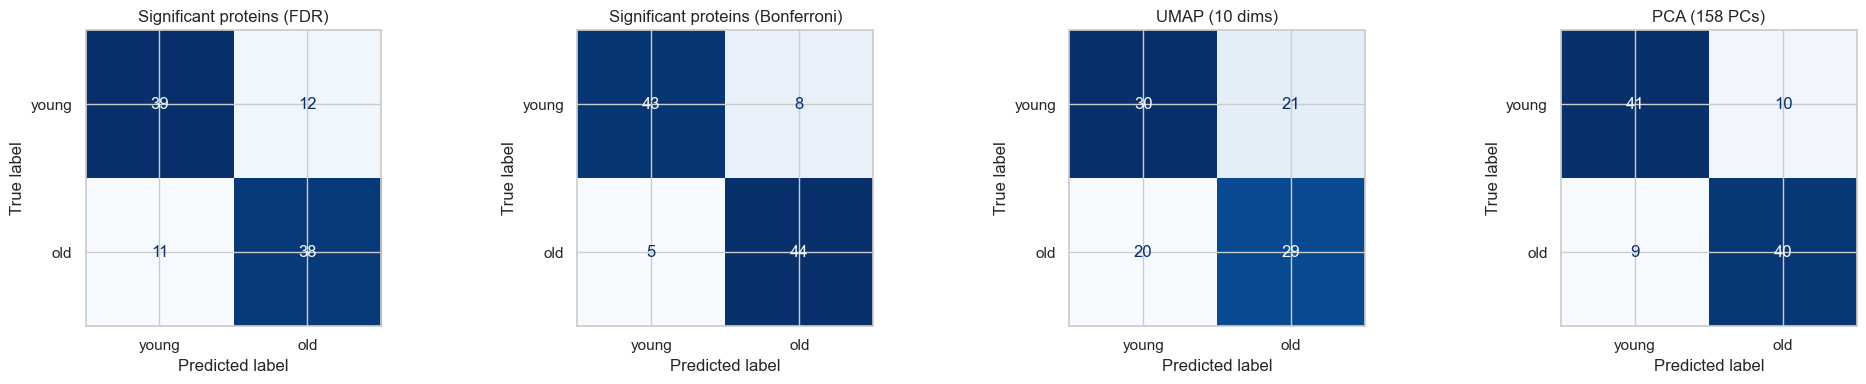

In [18]:
fig, axes = plt.subplots(1, len(confusion), figsize=(5 * len(confusion), 4))
for ax, (name, cm) in zip(axes, confusion.items()):
    ConfusionMatrixDisplay(cm, display_labels=["young", "old"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 5. Comparison of all feature sets

In [19]:
summary = reg_table[["n features", "test R²", "test MAE", "test MSE"]].copy()
summary.columns = ["regression: " + c for c in summary.columns]
cls = cls_table.copy(); cls.columns = ["classification: " + c for c in cls.columns]
print("Regression (organ age)"); display(summary.round(3))
print("Classification (young vs old)"); display(cls.round(3))

Regression (organ age)


,regression: n features,regression: test R²,regression: test MAE,regression: test MSE
features,,,,
All proteins,1463,0.736,0.079,0.009
Significant proteins (FDR),338,0.160,0.141,0.029
Significant proteins (Bonferroni),45,0.830,0.062,0.006
PCA (157 PCs),157,0.702,0.085,0.010
UMAP (10 dims),10,0.069,0.140,0.032


Classification (young vs old)


,classification: n features,classification: accuracy,classification: precision,classification: recall (sensitivity),classification: specificity
features,,,,,
Significant proteins (FDR),132,0.77,0.760,0.776,0.765
Significant proteins (Bonferroni),12,0.87,0.846,0.898,0.843
UMAP (10 dims),10,0.59,0.580,0.592,0.588
PCA (158 PCs),158,0.81,0.800,0.816,0.804


## 6. Discussion

**Organ age and the clinical variables.** Intestinal organ age is strongly linked to all three prodromal and motor
measures (Spearman, all FDR p < 0.001):
- **constipation**: rho = 0.81, the strongest: an "older" gut goes with more constipation;
- **smell (UPSIT)**: rho = −0.72: an older gut goes with a *lower* smell score, so worse smell (hyposmia);
- **motor symptoms (UPDRS III)**: rho = 0.54, positive but weaker.

The two non-motor symptoms that can appear years before a Parkinson's diagnosis (constipation and loss of smell) track
organ age more closely than motor severity does. That fits the "body-first" idea that, in some people, the disease
starts in the gut. These are synthetic data and correlations, so they show association, not cause.

**Which features predict organ age best (regression)?**

| Feature set | Features | Test R² | Test MAE |
| --- | --- | --- | --- |
| Significant proteins, Bonferroni | 45 | **0.83** | **0.062** |
| All proteins | 1,463 | 0.74 | 0.079 |
| PCA (80% of the variance) | 157 | 0.70 | 0.085 |
| Significant proteins, FDR | 338 | 0.16 | 0.141 |
| UMAP (10 dimensions) | 10 | 0.07 | 0.140 |

- **A few strong proteins win.** The 45 proteins that survive Bonferroni correction (led by ITGAV, VEGFA, FAS, IL6 and
  TNF) give the best predictions, and their train and test R² are close (0.86 vs 0.83): the model generalises.
- **More features are not always better.** All 1,463 proteins fit the training set *perfectly* (train R² = 1): with more
  features than patients, the model can memorise. It still does reasonably on the test set here, but the gap between
  1.0 and 0.74 is the sign of overfitting.
- **FDR alone keeps too much.** It selects 338 proteins, most only weakly related to organ age. With 338 features for
  400 training patients the model is unstable (train R² 0.98, test R² 0.16): the curse of dimensionality. Which
  correction to use depends on the goal: FDR to *find* candidate proteins, a stricter cut to *build a small model*.
- **PCA** keeps most of the information in 157 components and does almost as well as all proteins.
- **UMAP** does poorly here: it is unsupervised and keeps the structure that dominates the proteins, which is not organ
  age. Its 10 dimensions are made for seeing groups, not for a linear model.

**Young vs old organs (classification).**

| Feature set | Features | Accuracy | Precision | Sensitivity | Specificity |
| --- | --- | --- | --- | --- | --- |
| Significant proteins, Bonferroni | 12 | **0.87** | **0.85** | **0.90** | **0.84** |
| PCA (80% of the variance) | 158 | 0.81 | 0.80 | 0.82 | 0.80 |
| Significant proteins, FDR | 132 | 0.77 | 0.76 | 0.78 | 0.77 |
| UMAP (10 dimensions) | 10 | 0.59 | 0.58 | 0.59 | 0.59 |

The same pattern as the regression: the **12 proteins that survive Bonferroni** (ITGAV, VEGFA, FAS, IL6, TNF, MMP9,
OXT, JAM2, FKBP7, AGR2, NTRK3 and CRADD, mostly the same proteins that drive the regression) give the best classifier,
ahead of PCA. FDR keeps 132 proteins and does worse, and UMAP is close to chance. The groups are balanced (255 young,
245 old), so accuracy is a fair summary here, and sensitivity and specificity are similar: the models make both kinds
of mistake about equally often. Turning a continuous age into two classes throws information away, especially for
people near the 0.5 cut-off, which is one reason the regression is more informative.

**Take-home.** Keep everything that learns from data on the training set, compare feature sets on the same test
patients, and prefer the simplest model that generalises: here, a small set of strongly associated proteins (45 for the regression, 12 for the classification).

## References

1. Oh, H.S.-H., et al. (2023). *Organ aging signatures in the plasma proteome track health and disease*. **Nature**, 624, 164–172.
2. Borghammer, P., et al. (2021). *Neuropathological evidence of body-first vs. brain-first Lewy body disease*. **Neurobiology of Disease**, 161, 105557.